# Outputs for 6th Mag LGS

## Setup Materials

In [9]:
import pylab as plt
import numpy as np
from paarti.utils import maos_utils
from paarti import psfs, psf_plots
from pathlib import Path

# psf_x = [0, 5, 10, 15, 20, 25, 30, 35]  # arcsec
# psf_y = [0, 0,  0,  0,  0,  0,  0,  0,  0,  0]  # arcsec
# psf_wvl = [432, 544, 652, 810, 877, 1020, 1248, 1673, 2200]

ngs_gs_mag = 8
directory = f'/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_{ngs_gs_mag:.1f}'
seed = 1
print(directory)

%matplotlib inline

/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_8.0


# Strehl vs. Radius

In [6]:
if directory[-1] != '/':
    directory += '/'
mets = maos_utils.get_psf_metrics_over_field(directory, seed=seed)
x, y, w, strehl, fwhm_g, fwhm_e, r_ee50, r_ee80 = mets

Looking in /Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_8.0/ for simulation results...
xx =  0 yy =  0


In [75]:
r = np.sqrt(x**2 + y**2)
print(r.shape)
print(r)
print(w)
print(strehl)
print(strehl[0][-1])

(1, 5)
[[0. 0. 0. 0. 0.]]
[[0.8  1.   1.25 1.65 2.12]]
[[0.01719866 0.06365213 0.15908237 0.33402773 0.50607364]]
0.5060736418892487


In [ ]:
# Look for the tip-tilt error
p = Path(directory)
bin_files = list(p.glob("*.bin"))
res_bin_file = list(p.glob("*Res_*.bin"))[0]
print(bin_files)
print(res_bin_file)



res_bin_file

[PosixPath('/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_8.0/Resp_1.bin'), PosixPath('/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_8.0/Res_1.bin')]
/Users/nstieg/work/ao/keck/maos/keck_maos/TRICK_or_TREAT/TREAT/outputs/A_comparison_tt_mag_8.0/Res_1.bin


In [ ]:
# Import maos scripts to read .bin files
import sys
sys.path.append('/u/nstieg/code/latest_maos/maos/')
from scripts import readbin

In [50]:
# Read in the bin file with the results
res = readbin.readbin(str(res_bin_file))
print(res.shape)
print(res[0].shape) # Open loop WFV. Rows are piston removed wavefront variance (WFV), WFV in tip/tilt, piston/tip/tilt removed WFV - all in meters squared
print(res[1].shape) # Deprecated
print(res[2].shape) # Closed loop WFV in row vectors same as res[0]
print(res[3].shape) # Only in split tomography. Closed loop WFV. Rows are: WFV in LGS contains modes, WFV in NGS tip/tilt modes, WFV in NGS modes (including tip/tilt and additional modes controlled by NGS)

(4,)
(6999, 3)
(0,)
(6999, 3)
(6999, 4)


In [56]:
from astropy import units as u

In [69]:
tt_errors = res[2][:, 1] * u.m * u.m # This should be WFV in tip/tilt
other_errors = res[2][:, 2] * u.m * u.m # This should be WFV with piston & tip/tilt removed

tt_errors_nm = np.sqrt(tt_errors).to(u.nm)
other_errors_nm = np.sqrt(other_errors).to(u.nm)

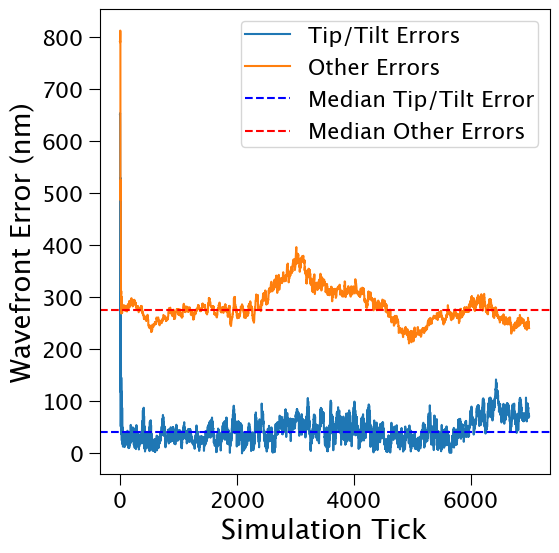

In [74]:
plt.plot(tt_errors_nm, label='Tip/Tilt Errors')
plt.plot(other_errors_nm, label='Other Errors')
burn_in_index = 300
median_tt_error = np.median(tt_errors_nm[burn_in_index:].to_value(u.nm))
median_other_error = np.median(other_errors_nm[burn_in_index:].to_value(u.nm))
plt.axhline(median_tt_error, color='blue', linestyle='--', label='Median Tip/Tilt Error')
plt.axhline(median_other_error, color='red', linestyle='--', label='Median Other Errors')
plt.xlabel("Simulation Tick")
plt.ylabel("Wavefront Error (nm)")
plt.legend()
plt.show()